# 07 — Ablation and McNemar's test

Three ablations use the frozen boosting settings from notebook 06. Each executed variant changes one component. Preprocessing is fit on the training period only. Ablation scores use the 2025 validation period, so the locked test is not used to compare feature sets.

The work-centre ablation does not fit a second model. Work Center is already absent from the frozen pipeline because the extract has no assignment time. The geographic ablation removes suburb, ward, and subcouncil. The imbalance ablation turns class weighting off. SMOTE is not used.

McNemar's test compares the frozen champion with the strongest approved Phase 5 comparator on the same locked-test cases. The comparator was named before the test scores were inspected. The exact binomial test is used when fewer than 25 cases disagree. Otherwise the continuity-corrected chi-square approximation is used.


## 1. Setup


In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
from IPython.display import Image, display

cwd = Path.cwd().resolve()
project_root = None
for candidate in [cwd, *cwd.parents]:
    if (candidate / "src" / "config.py").is_file():
        project_root = candidate
        break
if project_root is None:
    raise FileNotFoundError("Start JupyterLab from the project folder.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src import config
from src.evaluation import classification_scores
from src.neural import predict_feedforward, train_feedforward
from src.optimisation import (
    ablation_plan,
    assert_recorded_comparator,
    fit_frozen_boosting,
    full_feature_list,
    geographic_categorical_columns,
    render_phase6_report,
)
from src.preprocessing import (
    SOURCE_CATEGORICAL_COLUMNS,
    build_baseline_preprocessor,
    chronological_splits,
    logging_feature_frame,
)
from src.statistics import assert_aligned_observations, assert_matches_split, mcnemar_test, paired_correctness_counts, paired_correctness_table
from src.training import class_indices, probabilities_in_label_order, save_json, summarise_predictions
from src.visualization import plot_ablation_deltas, plot_confusion_matrix

config.set_random_seeds()
freeze_path = config.TABLES_DIR / "06_frozen_decision.json"
prediction_path = config.TABLES_DIR / "06_test_predictions.parquet"
candidate_path = config.TABLES_DIR / "06_candidate_metrics.csv"
search_path = config.TABLES_DIR / "06_search_summary.csv"
for required in (freeze_path, prediction_path, candidate_path, search_path):
    if not required.is_file():
        raise FileNotFoundError(
            "Notebook 07 reads the frozen decision and locked-test predictions from notebook 06. "
            f"Missing file: {required}."
        )
frozen = json.loads(freeze_path.read_text(encoding="utf-8"))
if not frozen["locked_test_scored"]:
    raise RuntimeError("Notebook 06 has not recorded the locked-test score.")
print(f"Frozen candidate: {frozen['selected']}")
print(f"Comparator named before the test scoring: {frozen['comparator']}")
print(f"Frozen max_iter: {frozen['max_iter']}")
print(f"Frozen parameters: {frozen['parameters']}")


Frozen candidate: untuned
Comparator named before the test scoring: multilayer_perceptron
Frozen max_iter: 12
Frozen parameters: {'l2_regularization': 1.0, 'learning_rate': 0.1, 'max_leaf_nodes': 31, 'min_samples_leaf': 50}


## 2. Ablations

The reference row is the frozen model's 2025 validation score from notebook 06. Changes are variant minus that reference. A negative macro-F1 change means the variant is lower than the full model on the validation period.


,experiment,component_changed,executed_fit,features,note
0,remove_geographic_features,"Suburb, Ward, and Sub_Council",True,"C3_Complaint_Type, created_day_of_week, create...","Retrained without suburb, ward, and subcouncil..."
1,remove_work_centre,Work Center,False,"C3_Complaint_Type, Suburb, Ward, Sub_Council, ...",Work Center is already excluded from the froze...
2,no_class_weight,class_weight,True,"C3_Complaint_Type, Suburb, Ward, Sub_Council, ...",Same features and frozen hyperparameters with ...


Retraining without suburb, ward, and subcouncil.


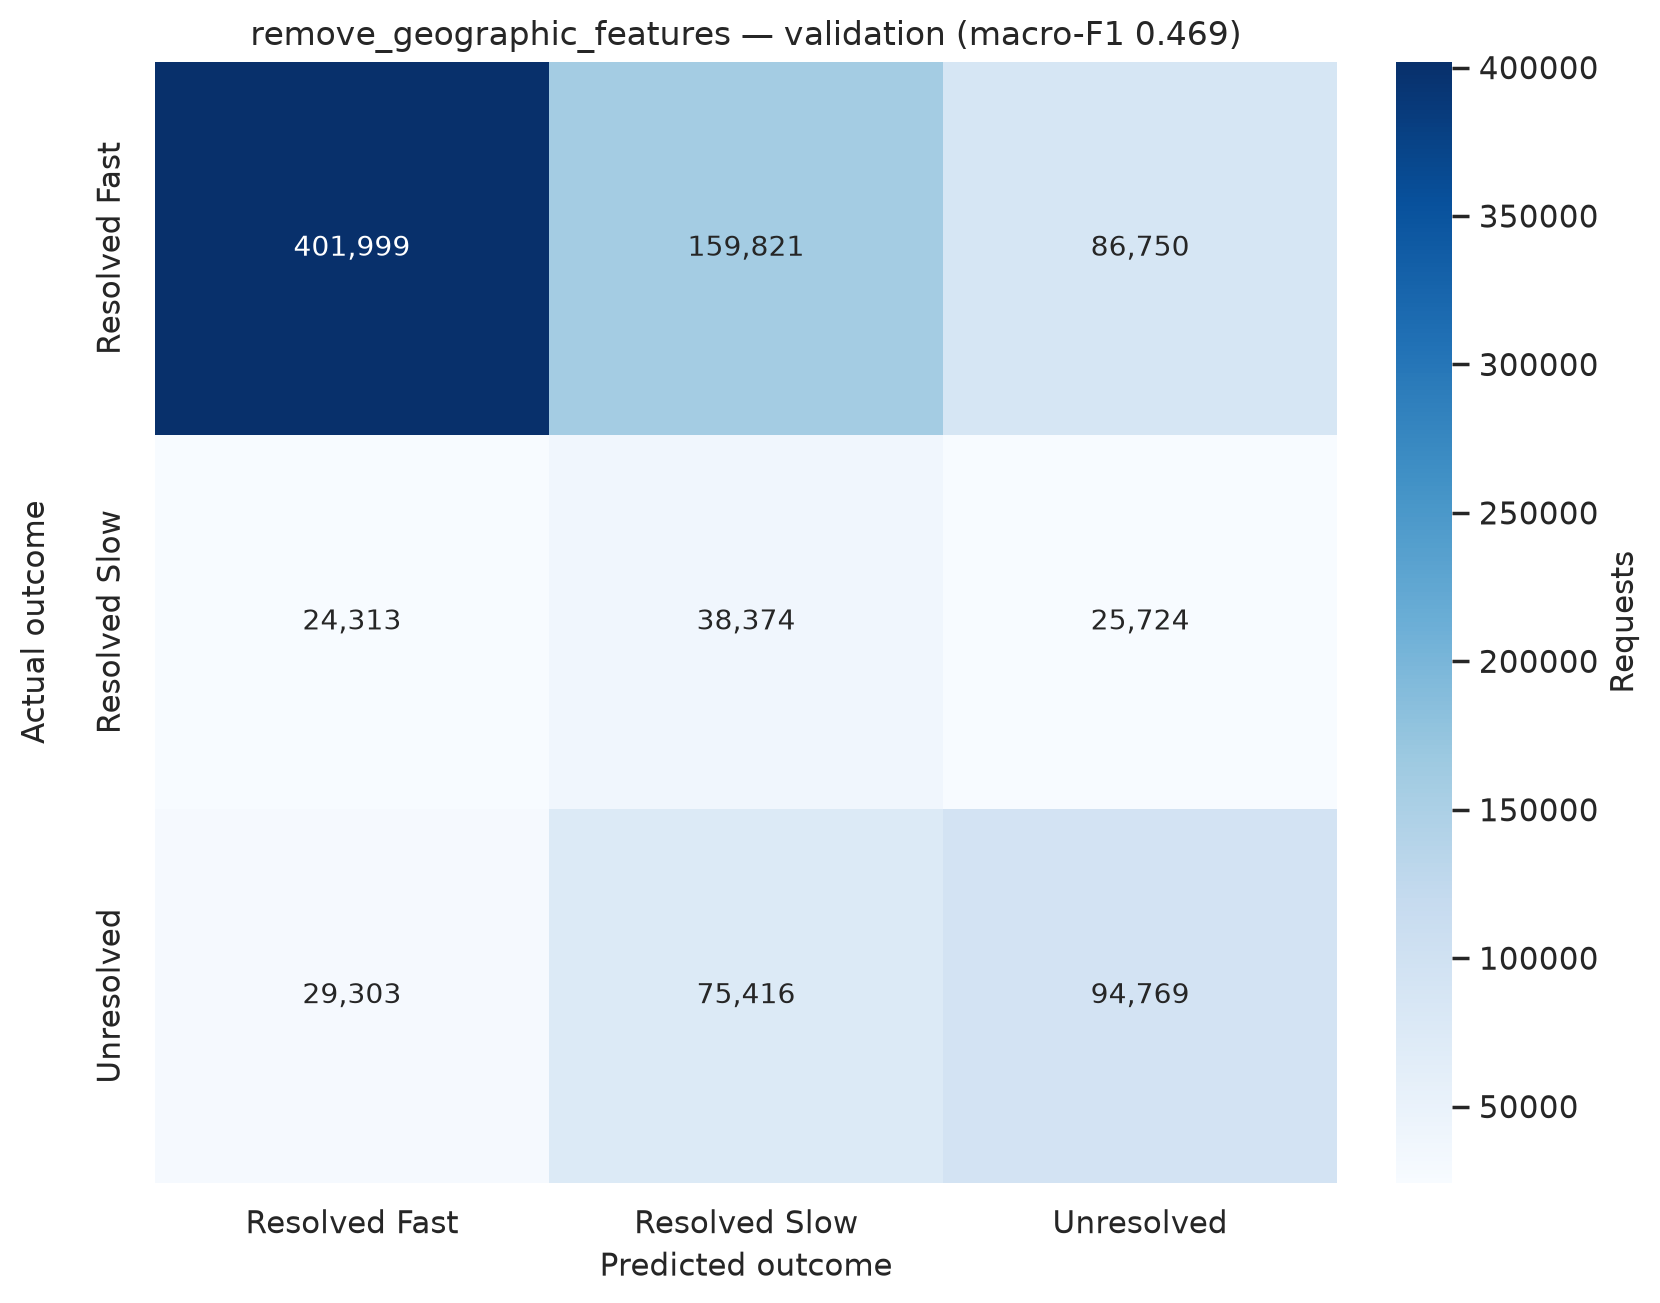

Retraining with class weighting turned off.


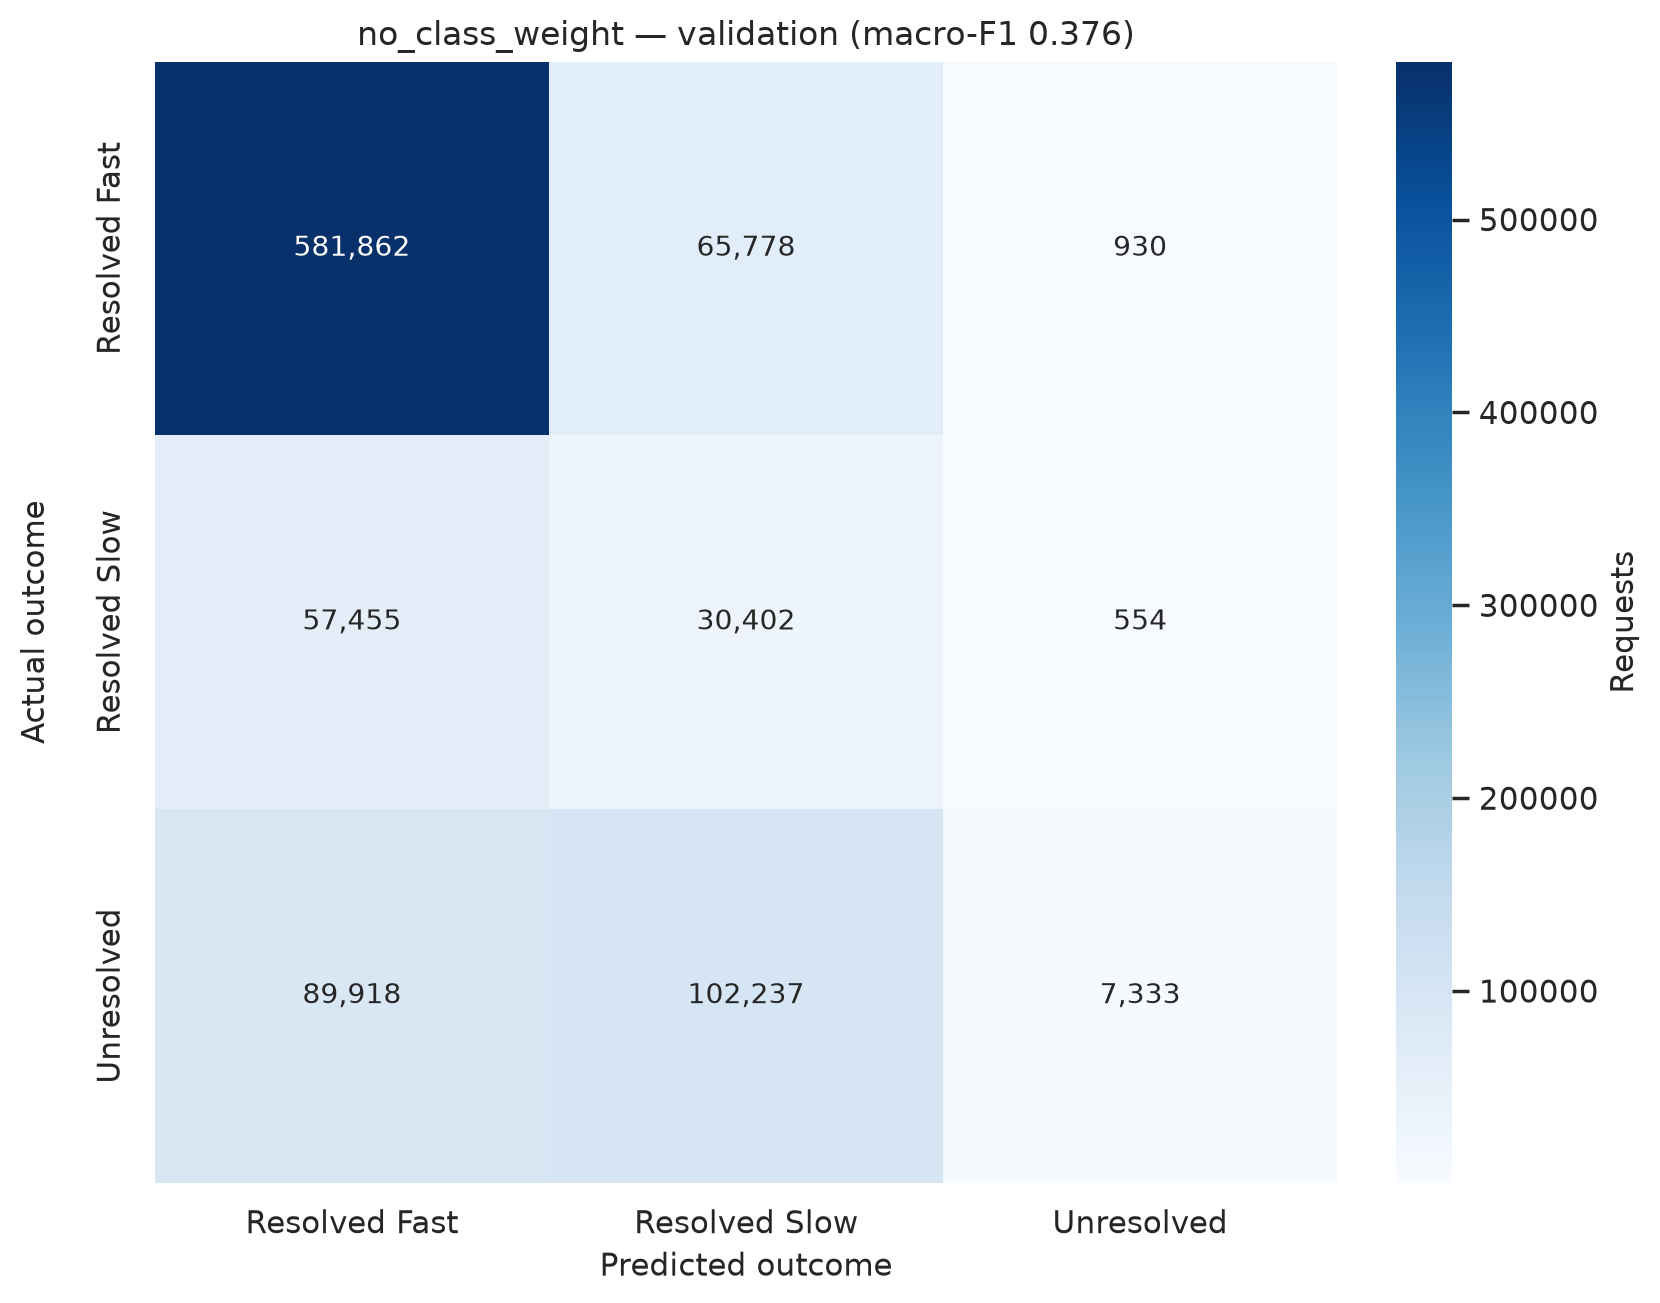

,experiment,executed_fit,macro_f1,recall_resolved_slow,recall_unresolved,delta_macro_f1,delta_recall_resolved_slow,delta_recall_unresolved,fit_seconds,note
0,remove_geographic_features,True,0.469,0.434,0.475,-0.008,0.002,0.033,4.517,"Retrained without suburb, ward, and subcouncil..."
1,remove_work_centre,False,0.477,0.432,0.442,0.000,0.000,0.000,5.026,Work Center is already excluded from the froze...
2,no_class_weight,True,0.376,0.344,0.037,-0.101,-0.089,-0.405,4.626,Same features and frozen hyperparameters with ...


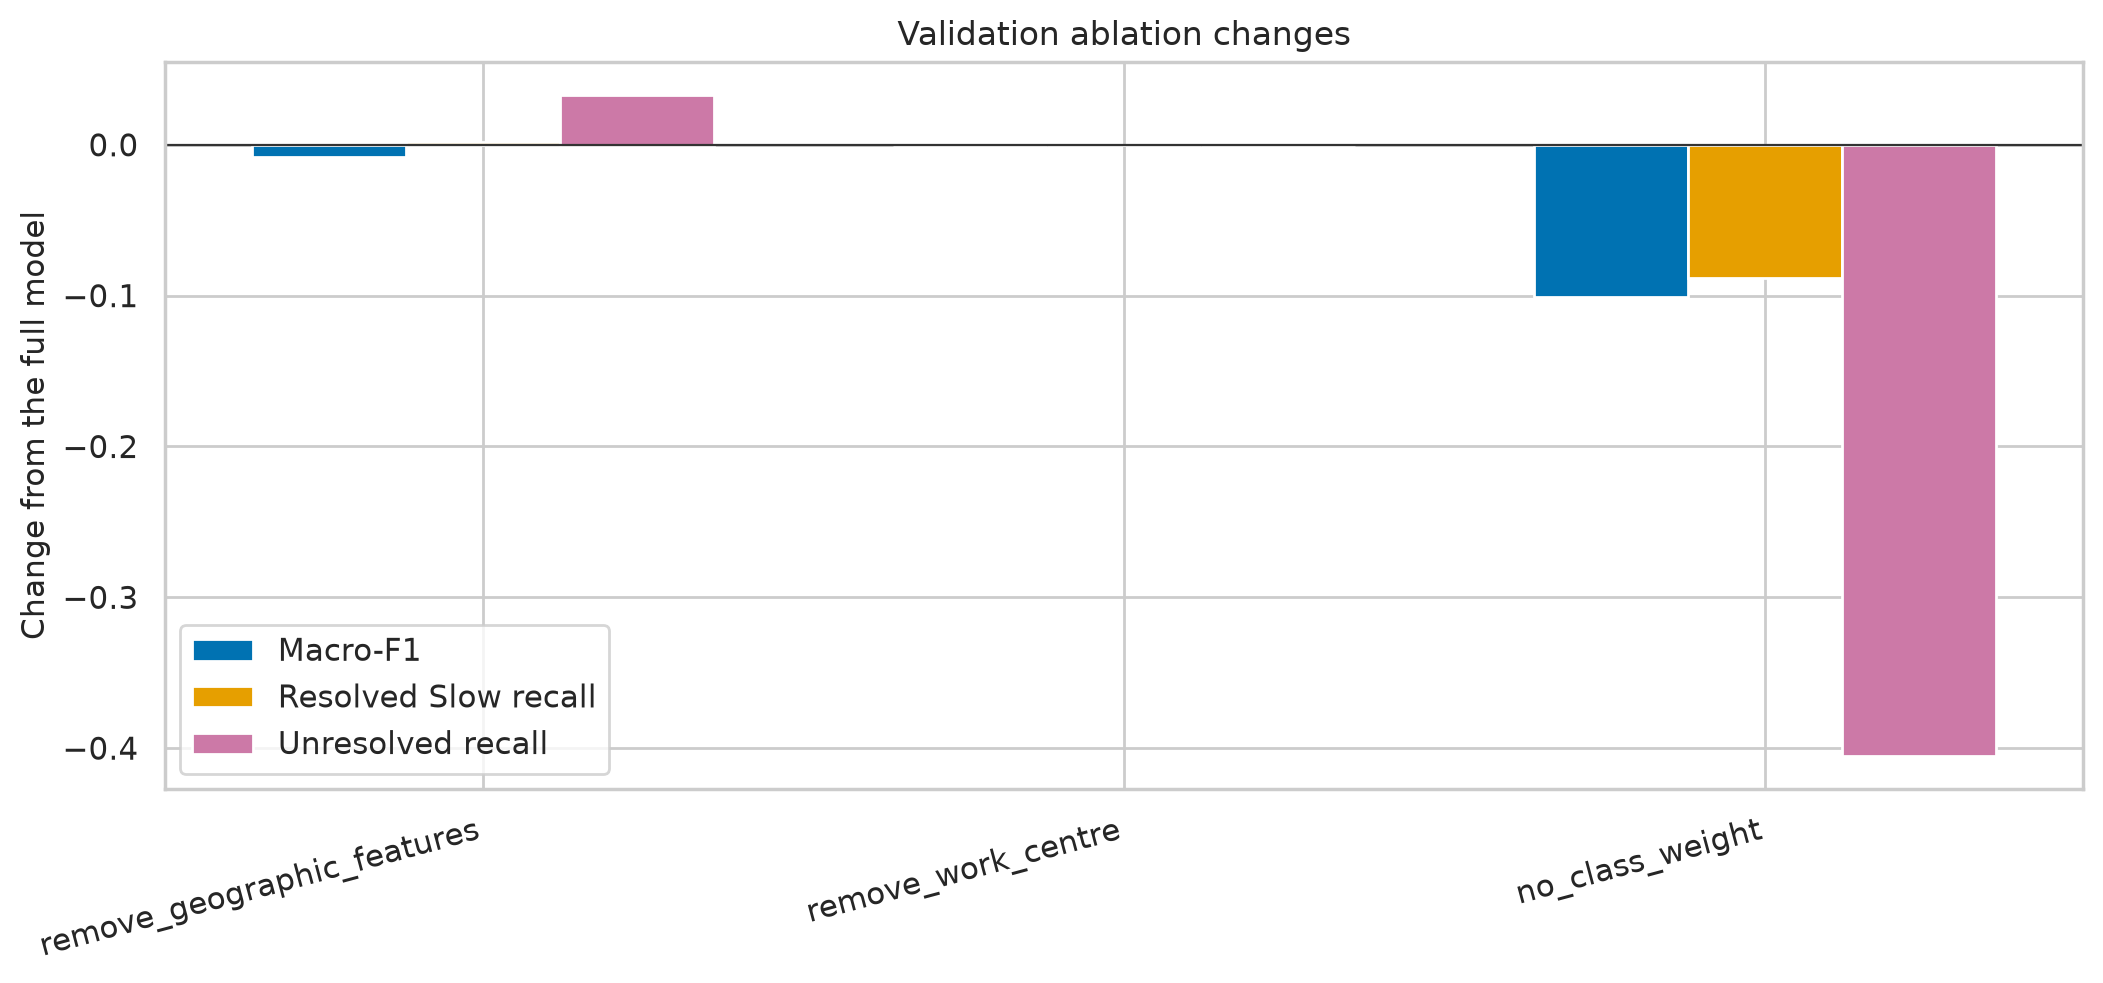

In [2]:
reference = pd.read_csv(candidate_path)
reference = reference.loc[
    reference["model"].eq(frozen["selected"]) & reference["split"].eq("validation")
].iloc[0]
plan = ablation_plan(full_feature_list())
display(plan)

source_columns = list(SOURCE_CATEGORICAL_COLUMNS) + ["Created_On_Date", "resolution_outcome"]
frame = pd.read_parquet(
    config.PROCESSED_DATA_DIR / "service_requests_labelled.parquet",
    columns=source_columns,
)
splits, _split_summary, _exclusions = chronological_splits(frame)
del frame
X_train = logging_feature_frame(splits["train"])
y_train = splits["train"]["resolution_outcome"].to_numpy()
X_validation = logging_feature_frame(splits["validation"])
y_validation = splits["validation"]["resolution_outcome"].to_numpy()
X_test = logging_feature_frame(splits["test"])
y_test = splits["test"]["resolution_outcome"].to_numpy()
test_index = splits["test"].index.to_numpy()
del splits


def validation_scores(model, encoder, model_name, fit_seconds):
    coded = encoder.transform(X_validation)
    predicted = model.predict(coded)
    probabilities = probabilities_in_label_order(model.predict_proba(coded), model.classes_)
    summary, per_class = summarise_predictions(
        y_validation,
        predicted,
        probabilities,
        model=model_name,
        split="validation",
        approval="approved",
        fit_seconds=fit_seconds,
    )
    scores = classification_scores(y_validation, predicted)
    _figure, path = plot_confusion_matrix(
        scores["confusion_matrix"],
        list(config.TARGET_LABELS),
        f"{model_name} — validation (macro-F1 {scores['macro_f1']:.3f})",
        f"07_confusion_{model_name}_validation.png",
    )
    display(Image(filename=str(path)))
    return summary, per_class


def ablation_row(experiment, summary, note, executed_fit):
    row = summary.iloc[0]
    return {
        "experiment": experiment,
        "executed_fit": executed_fit,
        "macro_f1": float(row["macro_f1"]),
        "recall_resolved_slow": float(row["recall_resolved_slow"]),
        "recall_unresolved": float(row["recall_unresolved"]),
        "delta_macro_f1": float(row["macro_f1"]) - float(reference["macro_f1"]),
        "delta_recall_resolved_slow": float(row["recall_resolved_slow"]) - float(reference["recall_resolved_slow"]),
        "delta_recall_unresolved": float(row["recall_unresolved"]) - float(reference["recall_unresolved"]),
        "fit_seconds": float(row["fit_seconds"]),
        "note": note,
    }


notes = plan.set_index("experiment")["note"].to_dict()
ablation_frames = []
per_class_frames = []

print("Retraining without suburb, ward, and subcouncil.", flush=True)
geo_encoder, geo_model, geo_seconds = fit_frozen_boosting(
    X_train,
    y_train,
    frozen["parameters"],
    max_iter=int(frozen["max_iter"]),
    categorical_columns=geographic_categorical_columns(),
)
geo_summary, geo_classes = validation_scores(
    geo_model, geo_encoder, "remove_geographic_features", geo_seconds
)
ablation_frames.append(ablation_row("remove_geographic_features", geo_summary, notes["remove_geographic_features"], True))
per_class_frames.append(geo_classes)

full_summary = pd.DataFrame([reference])
ablation_frames.append(
    ablation_row("remove_work_centre", full_summary, notes["remove_work_centre"], False)
)

print("Retraining with class weighting turned off.", flush=True)
weight_encoder, weight_model, weight_seconds = fit_frozen_boosting(
    X_train,
    y_train,
    frozen["parameters"],
    max_iter=int(frozen["max_iter"]),
    class_weight=None,
)
weight_summary, weight_classes = validation_scores(
    weight_model, weight_encoder, "no_class_weight", weight_seconds
)
ablation_frames.append(ablation_row("no_class_weight", weight_summary, notes["no_class_weight"], True))
per_class_frames.append(weight_classes)

ablation = pd.DataFrame(ablation_frames)
display(ablation.round(3))
_figure, ablation_path = plot_ablation_deltas(ablation)
display(Image(filename=str(ablation_path)))
ablation.to_csv(config.TABLES_DIR / "07_ablation_summary.csv", index=False)
pd.concat(per_class_frames, ignore_index=True).to_csv(
    config.TABLES_DIR / "07_ablation_per_class.csv", index=False
)


## 3. Comparator and McNemar's test

The comparator is the model recorded in the notebook 06 frozen decision. This notebook does not choose a different one. The selection rule is the highest validation macro-F1 among approved models other than the champion, with the same tie-break as the champion. The embedding network is excluded because it was not selected as champion and is not scored on the locked test. The recorded comparator is retrained with its Phase 5 procedure and scored once on the locked test. Champion predictions come from notebook 06. Both prediction columns must use the same source index, the same order, and the same labels. The test compares paired error outcomes. It does not by itself establish general superiority.


Retraining the multilayer perceptron.


mlp epoch 1: train_loss 0.6380, val_loss 1.4613, train_macro_f1 0.5834, val_macro_f1 0.4748


mlp epoch 2: train_loss 0.6042, val_loss 1.6222, train_macro_f1 0.6137, val_macro_f1 0.4762


mlp epoch 3: train_loss 0.5835, val_loss 1.7432, train_macro_f1 0.6326, val_macro_f1 0.4765


mlp epoch 4: train_loss 0.5711, val_loss 1.8221, train_macro_f1 0.6297, val_macro_f1 0.4727


...

Retrained validation macro-F1 at the restored epoch: 0.476. Phase 5 validation macro-F1: 0.476.
Restored epoch: 3. Epochs run: 6.


Retrained comparator validation scores:


,model,split,accuracy,macro_f1,weighted_f1,recall_resolved_fast,recall_resolved_slow,recall_unresolved,macro_roc_auc,macro_average_precision,approval,fit_seconds
0,multilayer_perceptron,validation,0.601,0.476,0.647,0.684,0.452,0.394,0.739,0.508,approved,340.243


,model,split,accuracy,macro_f1,weighted_f1,recall_resolved_fast,recall_resolved_slow,recall_unresolved,macro_roc_auc,macro_average_precision,approval,fit_seconds
0,multilayer_perceptron,test,0.606,0.495,0.634,0.702,0.458,0.345,0.731,0.529,approved,340.243


,model,split,label,precision,recall,f1,support
0,multilayer_perceptron,test,Resolved Fast,0.832,0.702,0.762,287131
1,multilayer_perceptron,test,Resolved Slow,0.220,0.458,0.297,65522
2,multilayer_perceptron,test,Unresolved,0.558,0.345,0.426,69380


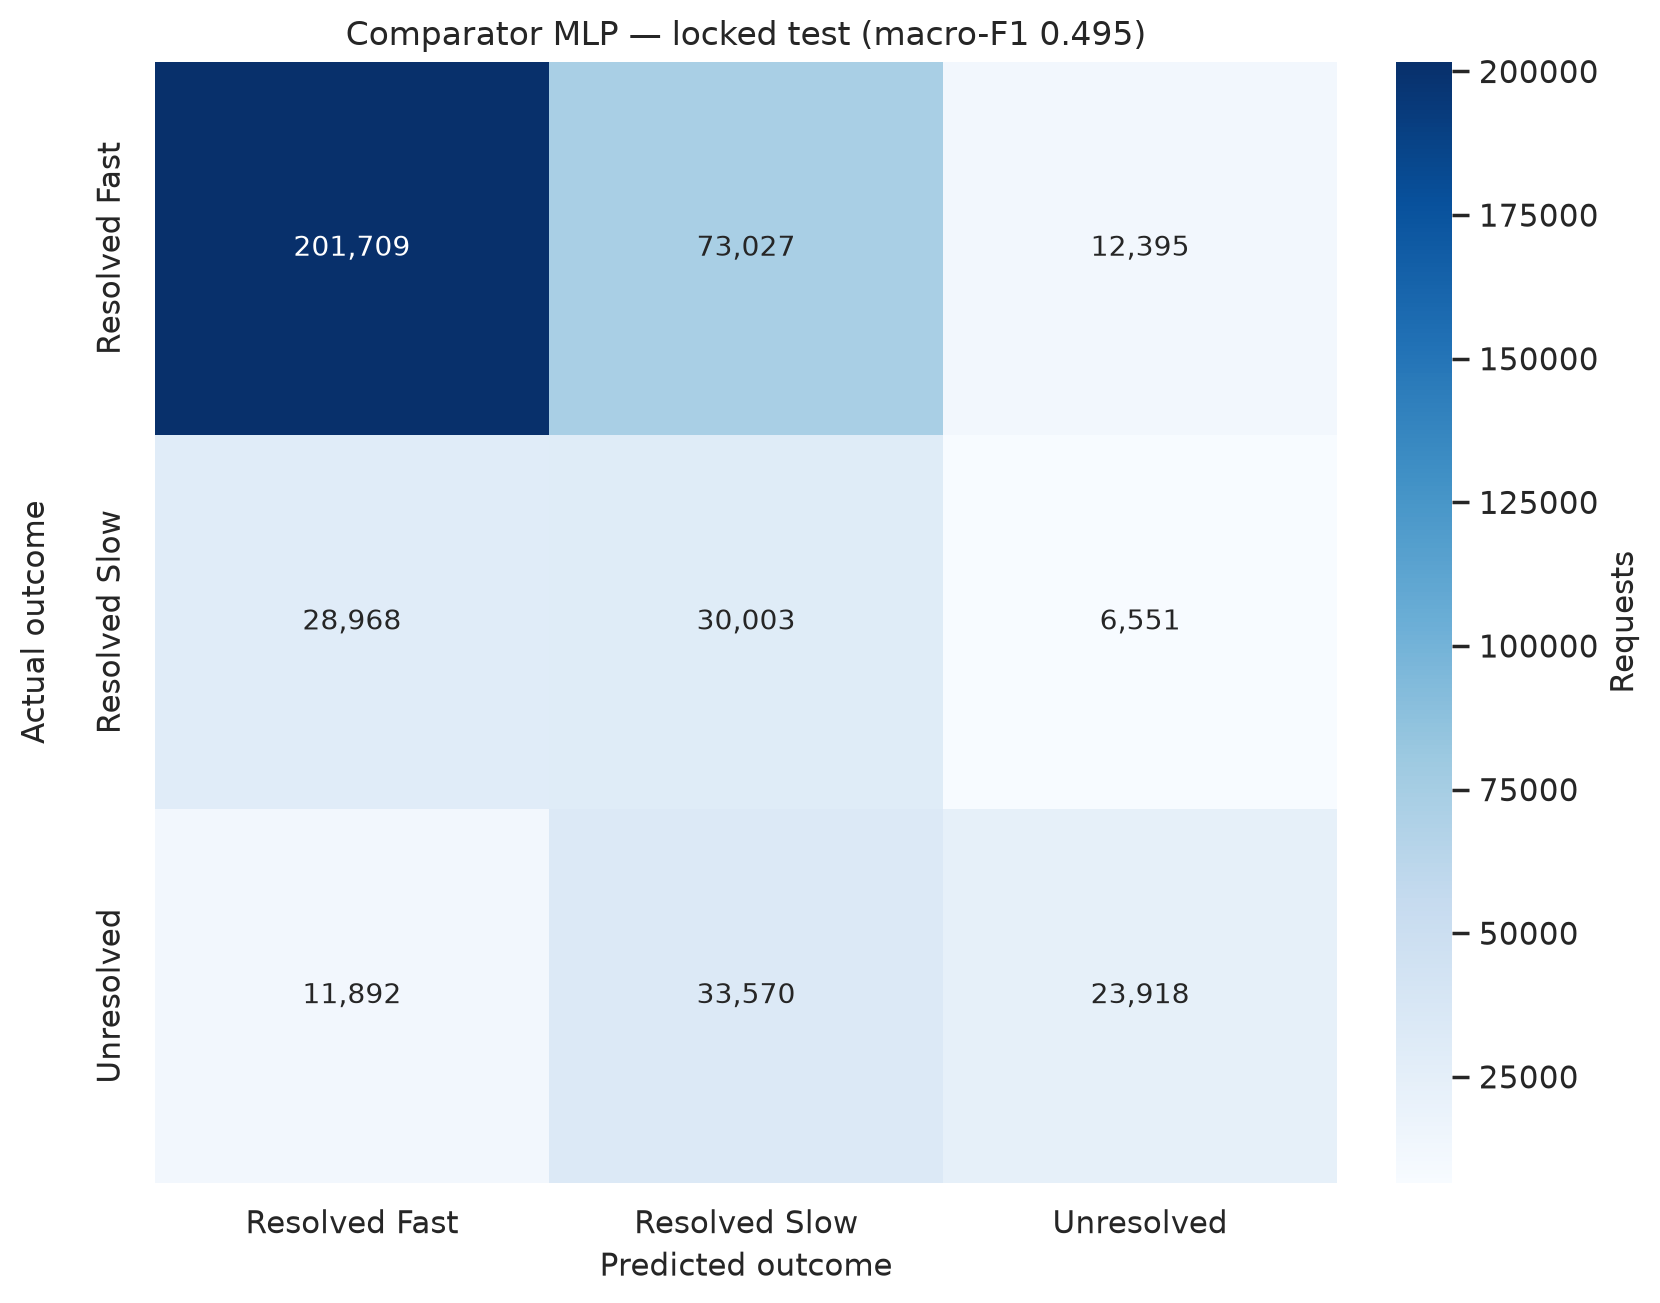

,rows,both_correct,champion_only,comparator_only,both_wrong
0,422033,233776,19282,21854,147121


chi-square with continuity correction
Statistic: 160.6875
p-value: 8.006e-37
Threshold: 0.05
The paired error rates differ at the 0.05 threshold. This does not show that one model is better on every class.
Accuracy difference, champion minus comparator: -0.0061
Macro-F1 difference, champion minus comparator: -0.0010
The p-value refers to the paired error rate. The accuracy and macro-F1 gaps are the practical comparison, including per-class recall in the tables above.
Wrote /workspace/evidence/reproducibility/notebooks/pr14_notebook07/reports/phase6_evaluation.md
# Phase 6 evaluation

The provisional champion family is histogram gradient boosting, from the Phase 5 validation macro-F1 ranking. Pending embedding results did not enter that choice. Tuning used chronological folds inside the training period only.

## Search

Random draws: 8. Seed: 42. The untuned Phase 5 settings were scored on the same folds. The score is mean macro-F1. Early stopping inside a fold uses that fold's later sl

In [3]:
phase5_comparison = pd.read_csv(config.TABLES_DIR / "05_model_comparison.csv")
record = assert_recorded_comparator(frozen, phase5_comparison)
if record["comparator"] != "multilayer_perceptron":
    raise RuntimeError(
        "The recorded comparator has no trainer in this notebook, so its locked-test predictions "
        "cannot be built here. Another model's predictions are not substituted. "
        f"Recorded comparator: {record['comparator']}."
    )
champion_predictions = pd.read_parquet(prediction_path)
assert_matches_split(champion_predictions, test_index, y_test)

preprocessor = build_baseline_preprocessor()
preprocessor.fit(X_train)
print("Retraining the multilayer perceptron.", flush=True)
mlp_result = train_feedforward(
    preprocessor.transform(X_train),
    y_train,
    preprocessor.transform(X_validation),
    y_validation,
    verbose=True,
)
print(
    f"Retrained validation macro-F1 at the restored epoch: {mlp_result['best_validation_macro_f1']:.3f}. "
    f"Phase 5 validation macro-F1: {float(frozen['comparator_phase5_validation_macro_f1']):.3f}."
)
print(f"Restored epoch: {mlp_result['best_epoch']}. Epochs run: {mlp_result['epochs_ran']}.")

validation_predicted, validation_probabilities, _loss = predict_feedforward(
    mlp_result["model"],
    preprocessor.transform(X_validation),
    class_indices(y_validation),
    batch_size=int(mlp_result["parameters"]["batch_size"]),
)
validation_summary, _validation_classes = summarise_predictions(
    y_validation,
    validation_predicted,
    validation_probabilities,
    model="multilayer_perceptron",
    split="validation",
    approval="approved",
    fit_seconds=mlp_result["fit_seconds"],
)
print("Retrained comparator validation scores:")
display(validation_summary.round(3))

test_predicted, test_probabilities, _loss = predict_feedforward(
    mlp_result["model"],
    preprocessor.transform(X_test),
    class_indices(y_test),
    batch_size=int(mlp_result["parameters"]["batch_size"]),
)
comparator_summary, comparator_classes = summarise_predictions(
    y_test,
    test_predicted,
    test_probabilities,
    model="multilayer_perceptron",
    split="test",
    approval="approved",
    fit_seconds=mlp_result["fit_seconds"],
    locked_test_authorised=True,
)
comparator_scores = classification_scores(y_test, test_predicted)
_figure, comparator_path = plot_confusion_matrix(
    comparator_scores["confusion_matrix"],
    list(config.TARGET_LABELS),
    f"Comparator MLP — locked test (macro-F1 {comparator_scores['macro_f1']:.3f})",
    "07_confusion_comparator_locked_test.png",
)
display(comparator_summary.round(3))
display(comparator_classes.round(3))
display(Image(filename=str(comparator_path)))

paired = champion_predictions.copy()
paired["comparator_predicted"] = test_predicted
assert_aligned_observations(champion_predictions, paired)
counts = paired_correctness_counts(
    paired["y_true"],
    paired["champion_predicted"],
    paired["comparator_predicted"],
)
result = mcnemar_test(counts)
count_table = paired_correctness_table(counts)
display(count_table)
print(result["method"])
print(f"Statistic: {result['statistic']}")
print(f"p-value: {result['p_value']:.4g}")
print(f"Threshold: {result['alpha']}")
print(result["conclusion"])

champion_test = pd.read_csv(config.TABLES_DIR / "06_locked_test_summary.csv").iloc[0]
accuracy_difference = float(champion_test["accuracy"]) - float(comparator_summary["accuracy"].iloc[0])
macro_difference = float(champion_test["macro_f1"]) - float(comparator_summary["macro_f1"].iloc[0])
print(f"Accuracy difference, champion minus comparator: {accuracy_difference:+.4f}")
print(f"Macro-F1 difference, champion minus comparator: {macro_difference:+.4f}")
print(
    "The p-value refers to the paired error rate. "
    "The accuracy and macro-F1 gaps are the practical comparison, including per-class recall in the tables above."
)

paired.to_parquet(config.TABLES_DIR / "07_paired_predictions.parquet", index=False)
count_table.to_csv(config.TABLES_DIR / "07_mcnemar_counts.csv", index=False)
pd.DataFrame([{**counts, **result, "comparator": frozen["comparator"]}]).to_csv(
    config.TABLES_DIR / "07_mcnemar_test.csv", index=False
)
comparator_summary.to_csv(config.TABLES_DIR / "07_comparator_locked_test_summary.csv", index=False)
comparator_classes.to_csv(config.TABLES_DIR / "07_comparator_locked_test_per_class.csv", index=False)
validation_summary.to_csv(config.TABLES_DIR / "07_comparator_retrained_validation.csv", index=False)

test_metrics = pd.concat(
    [pd.read_csv(config.TABLES_DIR / "06_locked_test_summary.csv"), comparator_summary],
    ignore_index=True,
)
mcnemar_payload = {
    "comparator": frozen["comparator"],
    **counts,
    **result,
    "accuracy_difference": accuracy_difference,
    "macro_f1_difference": macro_difference,
    "interpretation": (
        "The test compares paired error outcomes on the same locked-test observations. "
        "It does not establish that one model is better on every class, and it does not "
        "by itself establish general superiority."
    ),
    "split_id": record["split_id"],
    "test_rows": int(counts["rows"]),
}
report = render_phase6_report(
    pd.read_csv(search_path),
    pd.read_csv(candidate_path).loc[lambda frame: frame["split"].eq("validation")],
    frozen,
    test_metrics,
    ablation,
    mcnemar_payload,
)
report_path = config.REPORTS_DIR / "phase6_evaluation.md"
report_path.write_text(report, encoding="utf-8")
save_json({"frozen": frozen, "mcnemar": mcnemar_payload}, config.TABLES_DIR / "07_experiment_log.json")
print(f"Wrote {report_path}")
print(report)
